In [ ]:
# A) True NaN from the CSV
nan_counts = df.isna().sum()

# B) Sentinel-encoded missing values
sentinel_counts = (df == -9999).sum() + (df == -999).sum()

missing_report = pd.DataFrame({
    "true_nan": nan_counts,
    "sentinel_-9999/-999": sentinel_counts,
}).assign(
    total_missing=lambda x: x["true_nan"] + x["sentinel_-9999/-999"],
    pct_missing=lambda x: (x["total_missing"] / len(df) * 100).round(2),
).sort_values("pct_missing", ascending=False)

print(missing_report)

In [ ]:
print("Shape:", df.shape)
print("Columns:", list(df.columns))
print(df.head(3))
print(df.tail(3))
# Do the pickup_datetimes cluster or spread?
df["dt"] = pd.to_datetime(df["pickup_datetime"])
df["minute"] = df["dt"].dt.minute
print(df["minute"].value_counts().head(10))

In [ ]:
import pandas as pd, numpy as np

df["dt"] = pd.to_datetime(df["pickup_datetime"])
df["hour"] = df["dt"].dt.floor("h")

counts = df.groupby("hour").size()
print(counts.describe())
print("Hours with 1 row:", (counts == 1).sum())
print("Hours with 2 rows:", (counts == 2).sum())
print("Hours with 3+ rows:", (counts >= 3).sum())

# For the multi-row hours, are they duplicates or different values?
multi = counts[counts >= 2].index
print(df[df["hour"].isin(multi)][["pickup_datetime","tempm","hum","pressurem"]].head(20))

In [ ]:
"""
NYC Weather Data — Cleaning & Preprocessing
Input : D:\Weatherwalay\Day one\Weather.csv
Output: D:\Weatherwalay\Day one\weather_hourly_clean.csv
"""

import os
import pandas as pd
import numpy as np

# ============================================================
# 0. PATHS
# ============================================================
INPUT_PATH  = r"D:\Weatherwalay\Day one\Weather.csv"
OUTPUT_PATH = r"D:\Weatherwalay\Day one\weather_hourly_clean.csv"

if not os.path.exists(INPUT_PATH):
    raise FileNotFoundError(f"Not found: {INPUT_PATH}")

# ============================================================
# 1. LOAD
# ============================================================
df = pd.read_csv(INPUT_PATH)
print("Loaded:", df.shape)

df["dt"] = pd.to_datetime(df["pickup_datetime"])  # mislabeled column, is the datetime

# ============================================================
# 2. SNAP TO ONE ROW PER HOUR  (Wunderground reports at :51)
# ============================================================
df["hour"] = df["dt"].dt.floor("h")
df["dist_from_51"] = (df["dt"].dt.minute - 51).abs()

df = df.sort_values(["hour", "dist_from_51"])
hourly = (df.groupby("hour").first()
            .drop(columns=["dist_from_51", "dt", "pickup_datetime"]))

full_idx = pd.date_range(hourly.index.min(), hourly.index.max(), freq="h")
hourly = hourly.reindex(full_idx)
hourly.index.name = "datetime"

print("Hourly grid:", hourly.shape)
print("All-NaN hours (truly missing):", hourly["tempm"].isna().sum())

# ============================================================
# 3. DROP IMPERIAL DUPLICATES
# ============================================================
imperial = ["tempi", "dewpti", "wspdi", "wgusti", "visi", "pressurei",
            "windchilli", "heatindexi", "wdire"]
hourly = hourly.drop(columns=[c for c in imperial if c in hourly.columns])

# ============================================================
# 4. WIND DIRECTION  (0 = "Variable", NOT North)
#    Only fill isolated 1-hour dropouts on the unit circle.
# ============================================================
hourly.loc[hourly["wdird"] == 0, "wdird"] = np.nan
hourly["wind_is_variable"] = hourly["wdird"].isna().astype(int)

rad = np.deg2rad(hourly["wdird"])
sin_wd = np.sin(rad).interpolate(method="time", limit=1, limit_direction="both")
cos_wd = np.cos(rad).interpolate(method="time", limit=1, limit_direction="both")
hourly["wdird"] = (np.rad2deg(np.arctan2(sin_wd, cos_wd)) + 360) % 360

# ============================================================
# 5. INTERPOLATE GENUINELY-MISSING CONTINUOUS COLUMNS
# ============================================================
for col in ["tempm", "dewptm", "hum", "wspdm", "vism", "pressurem"]:
    hourly[col] = hourly[col].interpolate(method="time", limit=3, limit_direction="both")

for col in ["wspdm", "vism", "pressurem"]:
    hourly[col] = hourly[col].interpolate(method="time", limit=6, limit_direction="both")

# Edge rows
hourly["tempm"]  = hourly["tempm"].ffill().bfill()
hourly["dewptm"] = hourly["dewptm"].ffill().bfill()

# ============================================================
# 6. CONDITIONAL COLUMNS  (NaN = "not applicable", do NOT interpolate)
# ============================================================
no_precip = (hourly["rain"] == 0) & (hourly["snow"] == 0)
hourly.loc[hourly["precipm"].isna() & no_precip, "precipm"] = 0
hourly["precipm"] = hourly["precipm"].ffill(limit=1)

hourly["has_gust"]      = hourly["wgustm"].notna().astype(int)
hourly["has_windchill"] = hourly["windchillm"].notna().astype(int)
hourly["has_heatindex"] = hourly["heatindexm"].notna().astype(int)

# ============================================================
# 7. RENAME TO TARGET SCHEMA
# ============================================================
hourly = hourly.rename(columns={
    "tempm":      "temp_c",
    "dewptm":     "dewpt_c",
    "wspdm":      "wind_kph",
    "wgustm":     "gust_kph",
    "wdird":      "wind_dir_deg",
    "vism":       "vis_km",
    "pressurem":  "pressure_mbar",
    "windchillm": "windchill_c",
    "heatindexm": "heatindex_c",
    "precipm":    "precip_mm",
})

# ============================================================
# 8. DERIVED TIME FEATURES
# ============================================================
hourly["hour_of_day"]      = hourly.index.hour
hourly["day_of_week"]      = hourly.index.dayofweek
hourly["month"]            = hourly.index.month
hourly["is_weekend"]       = hourly["day_of_week"].isin([5, 6]).astype(int)
hourly["is_precipitating"] = (hourly["precip_mm"] > 0).astype(int)

# ============================================================
# 9. SELECT FINAL COLUMNS
# ============================================================
core = ["temp_c", "dewpt_c", "hum", "wind_kph", "gust_kph", "wind_dir_deg",
        "vis_km", "pressure_mbar", "windchill_c", "heatindex_c", "precip_mm"]
flags      = ["has_gust", "has_windchill", "has_heatindex",
              "wind_is_variable", "is_precipitating"]
time_feats = ["hour_of_day", "day_of_week", "month", "is_weekend"]

hourly_final = hourly[core + flags + time_feats]

# ============================================================
# 10. VERIFY & SAVE
# ============================================================
print("\nFinal shape:", hourly_final.shape)
print("\nRemaining NaN per column:")
print(hourly_final.isna().sum())

print("\nSummary of core columns:")
print(hourly_final[core].describe().T)

print("\nHead:")
print(hourly_final.head())

hourly_final.to_csv(OUTPUT_PATH)
print(f"\nSaved → {OUTPUT_PATH}")

In [ ]:
import pandas as pd
import numpy as np

PATH = r"D:\Weatherwalay\Day one\weather_hourly_clean.csv"
df = pd.read_csv(PATH, index_col="datetime", parse_dates=True)

# ----------------------------------------------------------------
# 1. Shape and columns
# ----------------------------------------------------------------
print("Shape:", df.shape)
print("\nColumns:")
for c in df.columns:
    print(f"  {c:<20} {df[c].dtype}")

# ----------------------------------------------------------------
# 2. Index integrity
# ----------------------------------------------------------------
print("\nIndex range:", df.index.min(), "→", df.index.max())
print("Index step distribution:")
print(df.index.to_series().diff().value_counts().head(3))

# ----------------------------------------------------------------
# 3. NaN profile
# ----------------------------------------------------------------
print("\nNaN counts:")
print(df.isna().sum())

# ----------------------------------------------------------------
# 4. hum sanity check (the new column)
# ----------------------------------------------------------------
print("\n=== hum ===")
print(df["hum"].describe())
print("Out-of-range (<0 or >100):",
      ((df["hum"] < 0) | (df["hum"] > 100)).sum())

# ----------------------------------------------------------------
# 5. Quick physics cross-checks
# ----------------------------------------------------------------
print("\n=== Physics checks (all should be 0) ===")
print("dewpoint > temp:",
      (df["dewpt_c"] > df["temp_c"] + 0.5).sum())
print("windchill active when temp > 15C:",
      ((df["has_windchill"] == 1) & (df["temp_c"] > 15)).sum())
print("heatindex active when temp < 20C:",
      ((df["has_heatindex"] == 1) & (df["temp_c"] < 20)).sum())
print("gust < wind speed:",
      (df["gust_kph"].notna() & (df["gust_kph"] < df["wind_kph"])).sum())

# ----------------------------------------------------------------
# 6. Summary stats for the core columns
# ----------------------------------------------------------------
core = ["temp_c", "dewpt_c", "hum", "wind_kph", "gust_kph",
        "wind_dir_deg", "vis_km", "pressure_mbar",
        "windchill_c", "heatindex_c", "precip_mm"]

print("\n=== Core column stats ===")
summary = df[core].describe(percentiles=[.05, .5, .95]).T
summary["nan_pct"] = (df[core].isna().mean() * 100).round(2)
summary["skew"]    = df[core].skew().round(2)
print(summary.round(2))

# ----------------------------------------------------------------
# 7. Sample rows
# ----------------------------------------------------------------
print("\nFirst 3 rows:")
print(df.head(3))

print("\nLast 3 rows:")
print(df.tail(3))

In [ ]:
# 1. hum sanity
print("=== hum ===")
print(df["hum"].describe())
print("Out of range:", ((df["hum"] < 0) | (df["hum"] > 100)).sum())

# 2. Physics checks
print("\n=== Physics checks (all should be 0) ===")
print("dewpoint > temp:",       (df["dewpt_c"] > df["temp_c"] + 0.5).sum())
print("windchill temp>15C:",    ((df["has_windchill"] == 1) & (df["temp_c"] > 15)).sum())
print("heatindex temp<20C:",    ((df["has_heatindex"] == 1) & (df["temp_c"] < 20)).sum())
print("gust < wind:",           (df["gust_kph"].notna() & (df["gust_kph"] < df["wind_kph"])).sum())

# 3. NaN profile
print("\n=== NaN counts ===")
print(df.isna().sum())

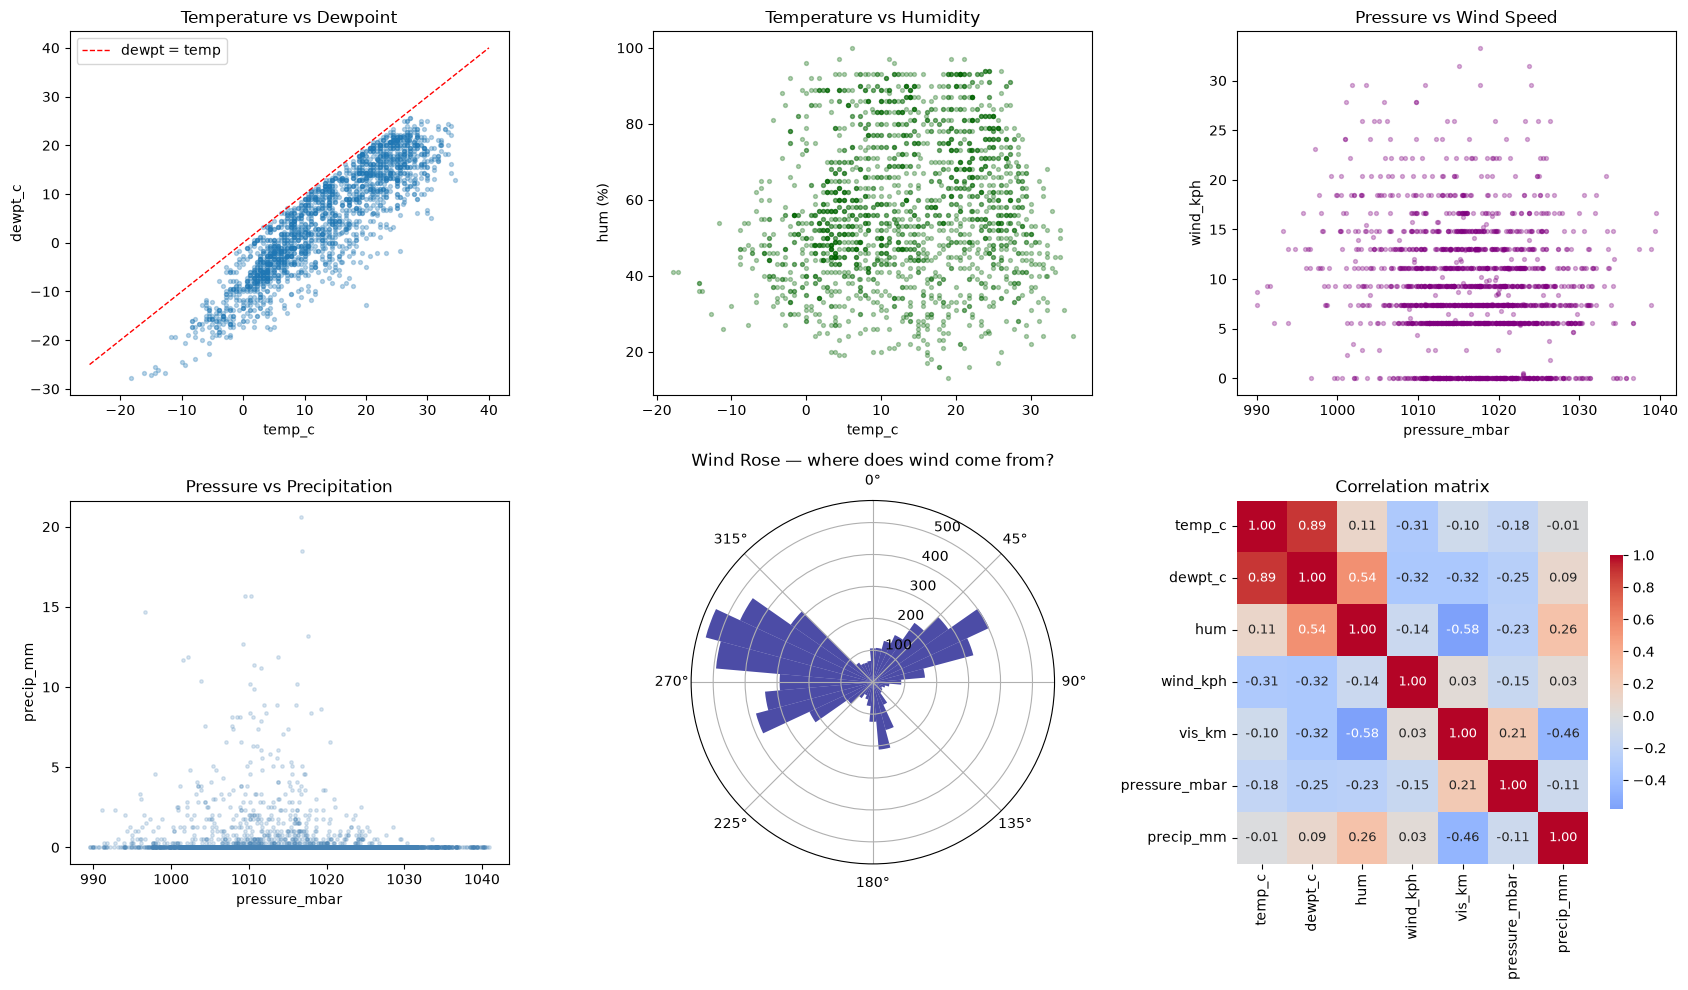

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(17, 10))

# ------------------------------------------------------------
# 1. Temperature vs Dewpoint
#    Should be nearly linear, dewpoint ≤ temperature
# ------------------------------------------------------------
ax = axes[0, 0]
samp = df[["temp_c", "dewpt_c"]].dropna().sample(2000, random_state=42)
ax.scatter(samp["temp_c"], samp["dewpt_c"], alpha=0.3, s=8)
lims = [-25, 40]
ax.plot(lims, lims, "r--", lw=1, label="dewpt = temp")
ax.set_xlabel("temp_c"); ax.set_ylabel("dewpt_c")
ax.set_title("Temperature vs Dewpoint")
ax.legend()

# ------------------------------------------------------------
# 2. Temperature vs Humidity
#    Should be inverse — hot afternoons have low RH
# ------------------------------------------------------------
ax = axes[0, 1]
samp = df[["temp_c", "hum"]].dropna().sample(2000, random_state=42)
ax.scatter(samp["temp_c"], samp["hum"], alpha=0.3, s=8, color="darkgreen")
ax.set_xlabel("temp_c"); ax.set_ylabel("hum (%)")
ax.set_title("Temperature vs Humidity")

# ------------------------------------------------------------
# 3. Pressure vs Wind speed
#    Low pressure → strong wind (strong pressure gradients)
# ------------------------------------------------------------
ax = axes[0, 2]
samp = df[["pressure_mbar", "wind_kph"]].dropna().sample(2000, random_state=42)
ax.scatter(samp["pressure_mbar"], samp["wind_kph"], alpha=0.3, s=8, color="purple")
ax.set_xlabel("pressure_mbar"); ax.set_ylabel("wind_kph")
ax.set_title("Pressure vs Wind Speed")

# ------------------------------------------------------------
# 4. Pressure vs Precipitation
#    Storms at low pressure → precip concentrated at low pressures
# ------------------------------------------------------------
ax = axes[1, 0]
ax.scatter(df["pressure_mbar"], df["precip_mm"], alpha=0.2, s=6, color="steelblue")
ax.set_xlabel("pressure_mbar"); ax.set_ylabel("precip_mm")
ax.set_title("Pressure vs Precipitation")

# ------------------------------------------------------------
# 5. Wind rose (polar histogram weighted by speed)
# ------------------------------------------------------------
ax = axes[1, 1]
wx = df.dropna(subset=["wind_dir_deg", "wind_kph"])
ax.remove()
ax = fig.add_subplot(2, 3, 5, projection="polar")
theta = np.deg2rad(wx["wind_dir_deg"])
radii = wx["wind_kph"]
bins_theta = np.linspace(0, 2*np.pi, 37)
counts, _ = np.histogram(theta, bins=bins_theta)
ax.bar(bins_theta[:-1], counts, width=np.diff(bins_theta),
       color="navy", alpha=0.7)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_title("Wind Rose — where does wind come from?")

# ------------------------------------------------------------
# 6. Correlation heatmap of continuous columns
# ------------------------------------------------------------
ax = axes[1, 2]
cols = ["temp_c", "dewpt_c", "hum", "wind_kph", "vis_km",
        "pressure_mbar", "precip_mm"]
corr = df[cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=ax, cbar_kws={"shrink": 0.7},
            annot_kws={"size": 9})
ax.set_title("Correlation matrix")

plt.tight_layout()
plt.show()

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# 1. Diurnal temperature cycle
df.groupby("hour_of_day")["temp_c"].mean().plot(
    ax=axes[0, 0], marker="o", color="crimson")
axes[0, 0].set_title("Avg Temperature by Hour of Day")
axes[0, 0].set_xlabel("hour"); axes[0, 0].set_ylabel("temp_c")
axes[0, 0].grid(alpha=0.3)

# 2. Diurnal humidity cycle
df.groupby("hour_of_day")["hum"].mean().plot(
    ax=axes[0, 1], marker="o", color="darkgreen")
axes[0, 1].set_title("Avg Humidity by Hour of Day")
axes[0, 1].set_xlabel("hour"); axes[0, 1].set_ylabel("hum (%)")
axes[0, 1].grid(alpha=0.3)

# 3. Temperature by day of week (check for weekday/weekend effects)
df.boxplot(column="temp_c", by="day_of_week", ax=axes[1, 0])
axes[1, 0].set_title("Temperature by Day of Week")
axes[1, 0].set_xlabel("day (0=Mon)"); axes[1, 0].set_ylabel("temp_c")

# 4. Temperature by month (verify seasonal pattern)
df.boxplot(column="temp_c", by="month", ax=axes[1, 1])
axes[1, 1].set_title("Temperature by Month")
axes[1, 1].set_xlabel("month"); axes[1, 1].set_ylabel("temp_c")

plt.suptitle("")
plt.tight_layout()
plt.show()